In [3]:
from google.colab import drive
import pandas as pd
import numpy as np
import sys
from datetime import datetime, time, timedelta

In [4]:
drive.mount('/content/gdrive')

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


In [11]:
pd.set_option('display.max_rows', None)

In [5]:
np.set_printoptions(threshold=sys.maxsize)

In [6]:
df = pd.read_csv('/content/gdrive/MyDrive/DASS_project/data/YouBike1.0/youbike即時資訊01.csv')
# df

/usr/local/lib/python3.8/dist-packages/IPython/core/interactiveshell.py:3326: DtypeWarning: Columns (6,7) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [7]:
df

,0304,金華公園,32,0,大安區,2018-04-30 15:49:35,25.029902000000,121.531235000000,金華街251號對面(金華公園),Daan Dist.,Jinhua Park,No.251， Jinhua St.,31,1,2018-04-30 15:49:35.1,2018-04-30 15:55:00,2018-04-30 15:49:35.2,2018-04-30
0,357,松友公園,26,13,信義區,2018-04-30 15:49:25,25.03423,121.57636,信義路六段76巷2弄16號(南側),Xinyi Dist.,@Songyou Park,No.16， Aly. 2， Ln. 76， Sec. 6， Xinyi Rd.,13,1,2018-04-30 15:49:35,2018-04-30 15:55:00,2018-04-30 15:49:35,2018-04-30
1,159,捷運西湖站(1號出口),36,14,內湖區,2018-04-30 15:49:44,25.082866,121.566695,環山路一段9巷/內湖路一段285巷(西南側),Neihu Dist.,MRT Xihu Sta. (Exit 1),Ln. 9， Sec. 1， Huanshan Rd./Ln. 285， Sec. 1， N...,22,1,2018-04-30 15:49:35,2018-04-30 15:55:00,2018-04-30 15:49:35,2018-04-30
2,188,社子國小,56,13,士林區,2018-04-30 15:49:19,25.090293,121.50189,延平北路六段/社中街(社子國小對面跨提便道橋下),Shilin Dist.,Taipei Municipal Shezi Elementary School,Sec. 6， Yanping N. Rd./Shezhong St.,43,1,2018-04-30 15:49:35,2018-04-30 15:55:00,2018-04-30 15:49:35,2018-04-30
3,259,南京遼寧街口,36,21,中山區,2018-04-30 15:49:41,25.051761,121.542168,南京東路三段189號對面(南京遼寧街口東南側),Zhongshan Dist.,Nanjing & Liaoning Intersection,No.189， Sec. 3， Nanjing E. Rd.(oppsite),15,1,2018-04-30 15:49:35,2018-04-30 15:55:00,2018-04-30 15:49:35,2018-04-30
4,204,臺北市立大學(天母校區),42,25,士林區,2018-04-30 15:49:45,25.113625,121.53742,士東路276號至280號對面人行道,Shilin Dist.,University of Taipei Tianmu Campus,No.276 to No. 280， Shidong Rd.， (opposite),15,1,2018-04-30 15:49:35,2018-04-30 15:55:00,2018-04-30 15:49:35,2018-04-30
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8641088,321,莒光大埔街口,32,12,中正區,2018-02-18 13:04:21,25.031334,121.505085,莒光路/大埔街口東北側(莒光大埔街口),Zhongzheng Dist.,Juguang & Dapu Intersection,Juguang Rd. / Dapu St. intersetion,19,1,2018-02-18 13:04:25,2018-02-18 13:10:00,2018-02-18 13:04:25,2018-02-18
8641089,73,酒泉延平路口,32,9,大同區,2018-02-18 13:04:40,25.072228,121.510195,延平北路四段/酒泉街(西北側),Datong Dist.,Jiuquan & Yanping Intersection,The N.W. side of Sec. 4， Yanping N. Rd. & Jiuq...,23,1,2018-02-18 13:04:25,2018-02-18 13:10:00,2018-02-18 13:04:25,2018-02-18
8641090,132,羅斯福新生南路口,88,35,大安區,2018-02-18 13:04:24,25.016031,121.533176,羅斯福路四段/新生南路三段交叉口,Daan Dist.,Roosevelt & Xinsheng S. Intersection,Sec. 4， Roosevelt Rd./Sec. 3， Xinsheng S. Rd.,53,1,2018-02-18 13:04:25,2018-02-18 13:10:00,2018-02-18 13:04:25,2018-02-18
8641091,192,捷運葫洲站(1號出口),44,27,內湖區,2018-02-18 13:04:37,25.072485,121.607955,康寧路三段/成功路五段450巷21弄(西北側)(捷運葫洲站1號出口前自行車停放區,Neihu Dist.,MRT Huzhou Sta. (Exit 1),Sec. 3， Kangning Rd./Aly. 21， Ln. 450， Sec. 5，...,16,1,2018-02-18 13:04:25,2018-02-18 13:10:00,2018-02-18 13:04:25,2018-02-18


### prepreprocess

In [8]:
# rename

name = ['station_number', 'station_name', 'total_num', 'current_num', 'district', 'date3', 'longtitude', 'latitude', 'address', 
        'districtE', 'stationNameE', 'addressE', 'empty', 'valid', 'date1', 'date2', 'time', 'date']
old_name = df.columns
for i in range(len(name)):
    df = df.rename(columns = {old_name[i] : name[i]})

In [9]:
df.columns

Index(['station_number', 'station_name', 'total_num', 'current_num',
       'district', 'date3', 'longtitude', 'latitude', 'address', 'districtE',
       'stationNameE', 'addressE', 'empty', 'valid', 'date1', 'date2', 'time',
       'date'],
      dtype='object')

In [10]:
df.head()

,station_number,station_name,total_num,current_num,district,date3,longtitude,latitude,address,districtE,stationNameE,addressE,empty,valid,date1,date2,time,date
0,357,松友公園,26,13,信義區,2018-04-30 15:49:25,25.03423,121.57636,信義路六段76巷2弄16號(南側),Xinyi Dist.,@Songyou Park,No.16， Aly. 2， Ln. 76， Sec. 6， Xinyi Rd.,13,1,2018-04-30 15:49:35,2018-04-30 15:55:00,2018-04-30 15:49:35,2018-04-30
1,159,捷運西湖站(1號出口),36,14,內湖區,2018-04-30 15:49:44,25.082866,121.566695,環山路一段9巷/內湖路一段285巷(西南側),Neihu Dist.,MRT Xihu Sta. (Exit 1),Ln. 9， Sec. 1， Huanshan Rd./Ln. 285， Sec. 1， N...,22,1,2018-04-30 15:49:35,2018-04-30 15:55:00,2018-04-30 15:49:35,2018-04-30
2,188,社子國小,56,13,士林區,2018-04-30 15:49:19,25.090293,121.50189,延平北路六段/社中街(社子國小對面跨提便道橋下),Shilin Dist.,Taipei Municipal Shezi Elementary School,Sec. 6， Yanping N. Rd./Shezhong St.,43,1,2018-04-30 15:49:35,2018-04-30 15:55:00,2018-04-30 15:49:35,2018-04-30
3,259,南京遼寧街口,36,21,中山區,2018-04-30 15:49:41,25.051761,121.542168,南京東路三段189號對面(南京遼寧街口東南側),Zhongshan Dist.,Nanjing & Liaoning Intersection,No.189， Sec. 3， Nanjing E. Rd.(oppsite),15,1,2018-04-30 15:49:35,2018-04-30 15:55:00,2018-04-30 15:49:35,2018-04-30
4,204,臺北市立大學(天母校區),42,25,士林區,2018-04-30 15:49:45,25.113625,121.53742,士東路276號至280號對面人行道,Shilin Dist.,University of Taipei Tianmu Campus,No.276 to No. 280， Shidong Rd.， (opposite),15,1,2018-04-30 15:49:35,2018-04-30 15:55:00,2018-04-30 15:49:35,2018-04-30


In [31]:
df.tail()

,station_number,station_name,total_num,current_num,district,date,longtitude,latitude,address,districtE,stationNameE,addressE,empty,valid,date1,date2,time,date3
8641088,321,莒光大埔街口,32,12,中正區,2018-02-18 13:04:21,25.031334,121.505085,莒光路/大埔街口東北側(莒光大埔街口),Zhongzheng Dist.,Juguang & Dapu Intersection,Juguang Rd. / Dapu St. intersetion,19,1,2018-02-18 13:04:25,2018-02-18 13:10:00,2018-02-18 13:04:25,2018-02-18
8641089,73,酒泉延平路口,32,9,大同區,2018-02-18 13:04:40,25.072228,121.510195,延平北路四段/酒泉街(西北側),Datong Dist.,Jiuquan & Yanping Intersection,The N.W. side of Sec. 4， Yanping N. Rd. & Jiuq...,23,1,2018-02-18 13:04:25,2018-02-18 13:10:00,2018-02-18 13:04:25,2018-02-18
8641090,132,羅斯福新生南路口,88,35,大安區,2018-02-18 13:04:24,25.016031,121.533176,羅斯福路四段/新生南路三段交叉口,Daan Dist.,Roosevelt & Xinsheng S. Intersection,Sec. 4， Roosevelt Rd./Sec. 3， Xinsheng S. Rd.,53,1,2018-02-18 13:04:25,2018-02-18 13:10:00,2018-02-18 13:04:25,2018-02-18
8641091,192,捷運葫洲站(1號出口),44,27,內湖區,2018-02-18 13:04:37,25.072485,121.607955,康寧路三段/成功路五段450巷21弄(西北側)(捷運葫洲站1號出口前自行車停放區,Neihu Dist.,MRT Huzhou Sta. (Exit 1),Sec. 3， Kangning Rd./Aly. 21， Ln. 450， Sec. 5，...,16,1,2018-02-18 13:04:25,2018-02-18 13:10:00,2018-02-18 13:04:25,2018-02-18
8641092,52,建國長春路口,30,11,中山區,2018-02-18 13:04:23,25.054761,121.536925,建國北路/長春路口(北側),Zhongshan Dist.,Jianguo & Changchun Intersection,The N. side of Jianguo N. Rd. & Changchun Rd.,18,1,2018-02-18 13:04:25,2018-02-18 13:10:00,2018-02-18 13:04:25,2018-02-18


In [12]:
df['station_name'].value_counts()

捷運南港軟體園區站(2號出口)    21746
捷運昆陽站(1號出口)        21746
南港國小               21746
捷運六張犁站             21746
世貿三館               21746
饒河夜市               21746
捷運劍南路站(2號出口)       21746
老松國小               21746
民生光復路口             21746
臺北市客家文化主題公園        21746
國家圖書館              21746
世貿二館               21746
大豐公園               21746
五常公園               21746
三民公園               21746
臺灣師範大學(圖書館)        21746
松山家商               21746
師範大學公館校區           21746
國興青年路口             21746
信義廣場(台北101)        21746
捷運行天宮站(3號出口)       21746
辛亥新生路口             21746
捷運後山埤站(1號出口)       21746
中山行政中心             21746
捷運台電大樓站(2號出口)      21746
捷運大安站              21746
凌雲市場               21746
福林公園               21746
建國長春路口             21746
捷運東門站(4號出口)        21746
金山愛國路口             21746
林安泰古厝              21746
松山車站               21746
捷運南港展覽館站(5號出口)     21746
捷運公館站(2號出口)        21746
福德公園               21746
捷運新北投站             21746
捷運臺大醫院(4號出口)       21746
興安華城               21746
基隆長興路口             21746


## 捷運公館站(2號出口)

In [11]:
df2 = df[df['station_name'] == '捷運公館站(2號出口)']

In [12]:
df2.shape

(21746, 18)

In [13]:
df2.columns

Index(['station_number', 'station_name', 'total_num', 'current_num',
       'district', 'date3', 'longtitude', 'latitude', 'address', 'districtE',
       'stationNameE', 'addressE', 'empty', 'valid', 'date1', 'date2', 'time',
       'date'],
      dtype='object')

In [14]:
df2.tail()

,station_number,station_name,total_num,current_num,district,date3,longtitude,latitude,address,districtE,stationNameE,addressE,empty,valid,date1,date2,time,date
8638984,45,捷運公館站(2號出口),30,5,大安區,2018-02-18 16:04:28,25.01476,121.534538,羅斯福路四段/舟山路(東北側),Daan Dist.,MRT Gongguan Sta.(Exit 2),The N.W. side of Roosevelt Rd.& Sinhai Rd.,25,1,2018-02-18 16:04:34,2018-02-18 16:10:00,2018-02-18 16:04:34,2018-02-18
8639736,45,捷運公館站(2號出口),30,12,大安區,2018-02-22 20:49:32,25.01476,121.534538,羅斯福路四段/舟山路(東北側),Daan Dist.,MRT Gongguan Sta.(Exit 2),The N.W. side of Roosevelt Rd.& Sinhai Rd.,16,1,2018-02-22 20:49:36,2018-02-22 20:55:00,2018-02-22 20:49:36,2018-02-22
8640260,45,捷運公館站(2號出口),30,10,大安區,2018-02-18 17:59:28,25.01476,121.534538,羅斯福路四段/舟山路(東北側),Daan Dist.,MRT Gongguan Sta.(Exit 2),The N.W. side of Roosevelt Rd.& Sinhai Rd.,20,1,2018-02-18 17:59:29,2018-02-18 18:05:00,2018-02-18 17:59:29,2018-02-18
8640501,45,捷運公館站(2號出口),30,12,大安區,2018-02-18 23:04:29,25.01476,121.534538,羅斯福路四段/舟山路(東北側),Daan Dist.,MRT Gongguan Sta.(Exit 2),The N.W. side of Roosevelt Rd.& Sinhai Rd.,18,1,2018-02-18 23:04:26,2018-02-18 23:10:00,2018-02-18 23:04:26,2018-02-18
8640870,45,捷運公館站(2號出口),30,7,大安區,2018-02-18 13:04:29,25.01476,121.534538,羅斯福路四段/舟山路(東北側),Daan Dist.,MRT Gongguan Sta.(Exit 2),The N.W. side of Roosevelt Rd.& Sinhai Rd.,23,1,2018-02-18 13:04:25,2018-02-18 13:10:00,2018-02-18 13:04:25,2018-02-18


In [16]:
df2.nunique()

total_num          1
current_num       31
empty             31
valid              2
time           21746
date              84
dtype: int64

In [15]:
to_drop = ['station_number', 'station_name', 'district', 'date3', 'longtitude', 'latitude', 'address', 'districtE',
       'stationNameE', 'addressE', 'date1', 'date2']
for col in to_drop:
  df2 = df2.drop(columns = col, axis = 1)
df2.columns

Index(['total_num', 'current_num', 'empty', 'valid', 'time', 'date'], dtype='object')

In [17]:
# from numpy import int32
numeric = ['total_num', 'current_num', 'empty']
cate = ['valid']
date = ['time', 'date']
for col in numeric:
  df2[col] = pd.to_numeric(df2[col], downcast= 'integer')
for col in cate:
  df2[col] = pd.Categorical(df2[col])
for col in date:
  df2[col] = pd.to_datetime(df2[col])

In [18]:
df2.head

<bound method NDFrame.head of          total_num  current_num  empty valid                time       date
125             30            6     22     1 2018-04-30 15:49:35 2018-04-30
522             30            2     27     1 2018-06-15 12:33:33 2018-06-15
790             30           28      1     1 2018-06-10 12:39:33 2018-06-10
1204            30            8     21     1 2018-04-30 21:44:34 2018-04-30
1589            30           10     19     1 2018-06-15 03:28:31 2018-06-15
...            ...          ...    ...   ...                 ...        ...
8638984         30            5     25     1 2018-02-18 16:04:34 2018-02-18
8639736         30           12     16     1 2018-02-22 20:49:36 2018-02-22
8640260         30           10     20     1 2018-02-18 17:59:29 2018-02-18
8640501         30           12     18     1 2018-02-18 23:04:26 2018-02-18
8640870         30            7     23     1 2018-02-18 13:04:25 2018-02-18

[21746 rows x 6 columns]>

### time show

In [46]:
df.dtypes

station_number     int64
station_name      object
total_num          int64
current_num        int64
district          object
date3             object
longtitude        object
latitude          object
address           object
districtE         object
stationNameE      object
addressE          object
empty              int64
valid              int64
date1             object
date2             object
time              object
date              object
dtype: object

In [51]:
d = pd.unique(df['date'])
d = np.sort(d)
d

array(['2018-01-01', '2018-01-02', '2018-01-03', '2018-01-08',
       '2018-01-11', '2018-01-12', '2018-01-15', '2018-01-17',
       '2018-01-19', '2018-01-21', '2018-01-23', '2018-01-25',
       '2018-01-27', '2018-01-29', '2018-01-30', '2018-02-01',
       '2018-02-03', '2018-02-05', '2018-02-07', '2018-02-09',
       '2018-02-11', '2018-02-13', '2018-02-16', '2018-02-18',
       '2018-02-20', '2018-02-22', '2018-02-24', '2018-02-26',
       '2018-02-28', '2018-03-02', '2018-03-04', '2018-03-06',
       '2018-03-08', '2018-03-10', '2018-03-12', '2018-03-14',
       '2018-03-16', '2018-03-18', '2018-03-19', '2018-03-21',
       '2018-03-23', '2018-03-25', '2018-03-27', '2018-03-29',
       '2018-03-31', '2018-04-02', '2018-04-05', '2018-04-07',
       '2018-04-09', '2018-04-11', '2018-04-13', '2018-04-15',
       '2018-04-17', '2018-04-19', '2018-04-20', '2018-04-22',
       '2018-04-24', '2018-04-26', '2018-04-29', '2018-04-30',
       '2018-05-01', '2018-05-02', '2018-05-10', '2018-

In [55]:
d = pd.unique(df['time'])
d = np.sort(d)
d

array(['2018-01-01 23:59:23', '2018-01-02 00:04:24',
       '2018-01-02 00:09:28', '2018-01-02 00:14:32',
       '2018-01-02 00:19:32', '2018-01-02 00:24:25',
       '2018-01-02 00:29:38', '2018-01-02 00:34:37',
       '2018-01-02 00:39:26', '2018-01-02 00:44:43',
       '2018-01-02 00:49:38', '2018-01-02 00:54:55',
       '2018-01-02 00:59:14', '2018-01-02 01:04:16',
       '2018-01-02 01:08:19', '2018-01-02 01:14:36',
       '2018-01-02 01:19:31', '2018-01-02 01:24:40',
       '2018-01-02 01:29:27', '2018-01-02 01:34:38',
       '2018-01-02 01:39:30', '2018-01-02 01:44:33',
       '2018-01-02 01:49:26', '2018-01-02 01:54:33',
       '2018-01-02 01:59:23', '2018-01-02 02:04:41',
       '2018-01-02 02:09:23', '2018-01-02 02:14:40',
       '2018-01-02 02:19:18', '2018-01-02 02:24:55',
       '2018-01-02 02:29:21', '2018-01-02 02:33:43',
       '2018-01-02 02:39:32', '2018-01-02 02:44:23',
       '2018-01-02 02:49:20', '2018-01-02 02:54:18',
       '2018-01-02 02:59:44', '2018-01-02 03:0

### create day of week

In [19]:
df2.shape[0]

21746

In [20]:
temp = np.zeros(df2.shape[0])
df2['dayofweek'] = temp

In [21]:
temp = df2['date'].dt.dayofweek

In [22]:
df2['dayofweek'] = temp

In [23]:
df2.groupby('dayofweek').size()

dayofweek
0    3301
1    3511
2    2764
3    3326
4    3462
5    2173
6    3209
dtype: int64

In [25]:
df2.head()

,total_num,current_num,empty,valid,time,date,dayofweek
125,30,6,22,1,2018-04-30 15:49:35,2018-04-30,0
522,30,2,27,1,2018-06-15 12:33:33,2018-06-15,4
790,30,28,1,1,2018-06-10 12:39:33,2018-06-10,6
1204,30,8,21,1,2018-04-30 21:44:34,2018-04-30,0
1589,30,10,19,1,2018-06-15 03:28:31,2018-06-15,4


### create 10 min data

In [26]:
def setTime(dataframe, lowerBound, upperBound):
    '''take df and return a pandas series (average of features in timeseries Interval) ''' 
    df = dataframe.copy(deep=True)
    samplesInInterval = df.loc[(df['time'] >= lowerBound) & (df['time'] < upperBound)]
    if samplesInInterval.shape[0] == 1:
        sample = samplesInInterval.copy(deep=True)
        sample['time'] = lowerBound
    
        return sample

    elif samplesInInterval.shape[0] == 0:

        pass

    else:
        s = samplesInInterval.copy(deep=True)
        sample = s.iloc[0].to_frame().transpose()
        sample['current_num'] = round(s['current_num'].mean(), 1)
        sample['empty'] = round(s['empty'].mean(), 1)
        sample['time'] = lowerBound

        return sample

In [27]:
times = []
ts = datetime(2018, 1, 1, 0, 0, 0)
while ts <= datetime(2018, 6, 15, 0, 0, 0):
    times.append(ts)
    ts += timedelta(minutes=10)

In [28]:
# df3 = []
perStation = []
count = 0
previous = df2.iloc[0].to_frame().transpose()
for j in range(len(times)-1):
  tenMin = setTime(df2, times[j], times[j+1])
  if isinstance(tenMin, pd.DataFrame):
    perStation.append(tenMin)
    previous = tenMin.copy()
            
  else:
    sample = previous
    sample['time'] = times[j]
    perStation.append(previous)
    count += 1
df3 = pd.concat(perStation, axis=0, ignore_index=True)
# newStationDataframe.append(newStation)
print('missing 10min at :', count)

missing 10min at : 12611


In [88]:
type(df3)

pandas.core.frame.DataFrame

In [29]:
df3

,total_num,current_num,empty,valid,time,date,dayofweek
0,30,6,22,1,2018-01-01 23:40:00,2018-04-30,0
1,30,6,22,1,2018-01-01 23:40:00,2018-04-30,0
2,30,6,22,1,2018-01-01 23:40:00,2018-04-30,0
3,30,6,22,1,2018-01-01 23:40:00,2018-04-30,0
4,30,6,22,1,2018-01-01 23:40:00,2018-04-30,0
...,...,...,...,...,...,...,...
23755,30,17,12,1,2018-06-14 23:10:00,2018-06-14,3
23756,30,17,12,1,2018-06-14 23:30:00,2018-06-14,3
23757,30,17,12,1,2018-06-14 23:30:00,2018-06-14,3
23758,30,13,16,1,2018-06-14 23:40:00,2018-06-14,3


In [30]:
df3 = df3.drop(columns = 'date', axis =1)

In [33]:
df3['current_num'].value_counts()

2.0     1355
0.5     1332
12.0    1181
2.5     1057
1.5      943
        ... 
12.4       1
27.7       1
20.7       1
28.3       1
26.7       1
Name: current_num, Length: 116, dtype: int64

In [34]:
df3.to_csv('/content/gdrive/MyDrive/DASS_project/data/youbike1.0_10min.csv')

In [35]:
import matplotlib.pyplot as plt

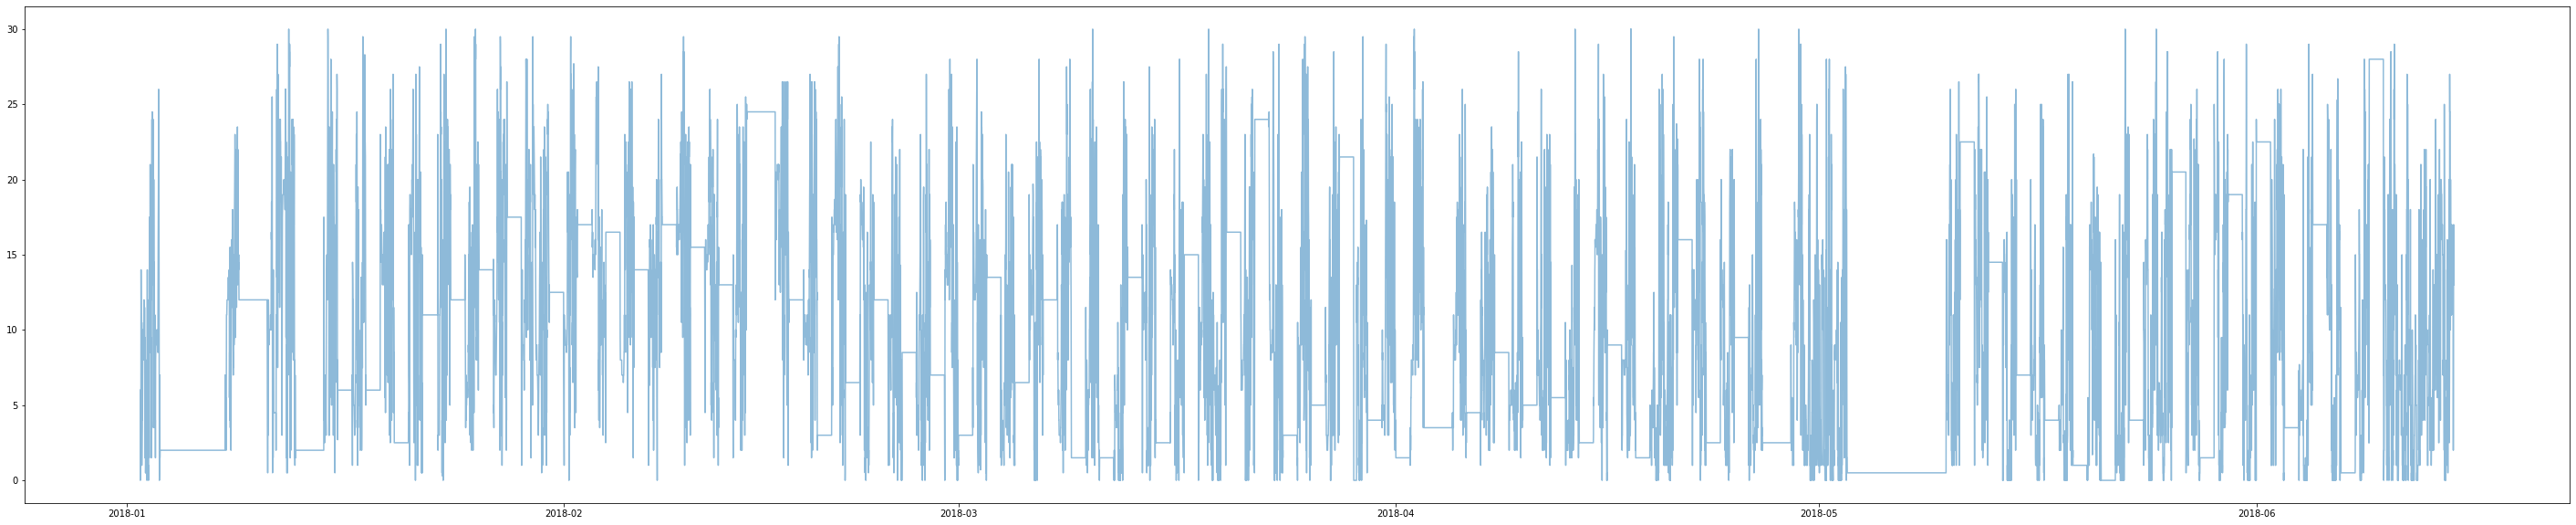

In [40]:
plt.figure(figsize = (50,10))
plt.plot(df3['time'], df3['current_num'], alpha=0.5)
plt.show()